In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose

In [46]:
df = pd.read_csv("Microsoft_Stock.csv")
df.head()

,Date,Open,High,Low,Close,Volume
0,4/1/2015 16:00:00,40.60,40.76,40.31,40.72,36865322
1,4/2/2015 16:00:00,40.66,40.74,40.12,40.29,37487476
2,4/6/2015 16:00:00,40.34,41.78,40.18,41.55,39223692
3,4/7/2015 16:00:00,41.61,41.91,41.31,41.53,28809375
4,4/8/2015 16:00:00,41.48,41.69,41.04,41.42,24753438


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1511 entries, 0 to 1510
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1511 non-null   object 
 1   Open    1511 non-null   float64
 2   High    1511 non-null   float64
 3   Low     1511 non-null   float64
 4   Close   1511 non-null   float64
 5   Volume  1511 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 71.0+ KB


In [48]:
df.describe()

,Open,High,Low,Close,Volume
count,1511.000000,1511.000000,1511.000000,1511.000000,1.511000e+03
mean,107.385976,108.437472,106.294533,107.422091,3.019863e+07
std,56.691333,57.382276,55.977155,56.702299,1.425266e+07
min,40.340000,40.740000,39.720000,40.290000,1.016120e+05
25%,57.860000,58.060000,57.420000,57.855000,2.136213e+07
50%,93.990000,95.100000,92.920000,93.860000,2.662962e+07
75%,139.440000,140.325000,137.825000,138.965000,3.431962e+07
max,245.030000,246.130000,242.920000,244.990000,1.352271e+08


In [49]:
df.max()

,0
Date,9/9/2020 16:00:00
Open,245.03
High,246.13
Low,242.92
Close,244.99
Volume,135227059


In [50]:
df.isna().sum()

,0
Date,0
Open,0
High,0
Low,0
Close,0
Volume,0


In [51]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
df.head()

,Date,Open,High,Low,Close,Volume
0,2015-04-01 16:00:00,40.60,40.76,40.31,40.72,36865322
1,2015-04-02 16:00:00,40.66,40.74,40.12,40.29,37487476
2,2015-04-06 16:00:00,40.34,41.78,40.18,41.55,39223692
3,2015-04-07 16:00:00,41.61,41.91,41.31,41.53,28809375
4,2015-04-08 16:00:00,41.48,41.69,41.04,41.42,24753438


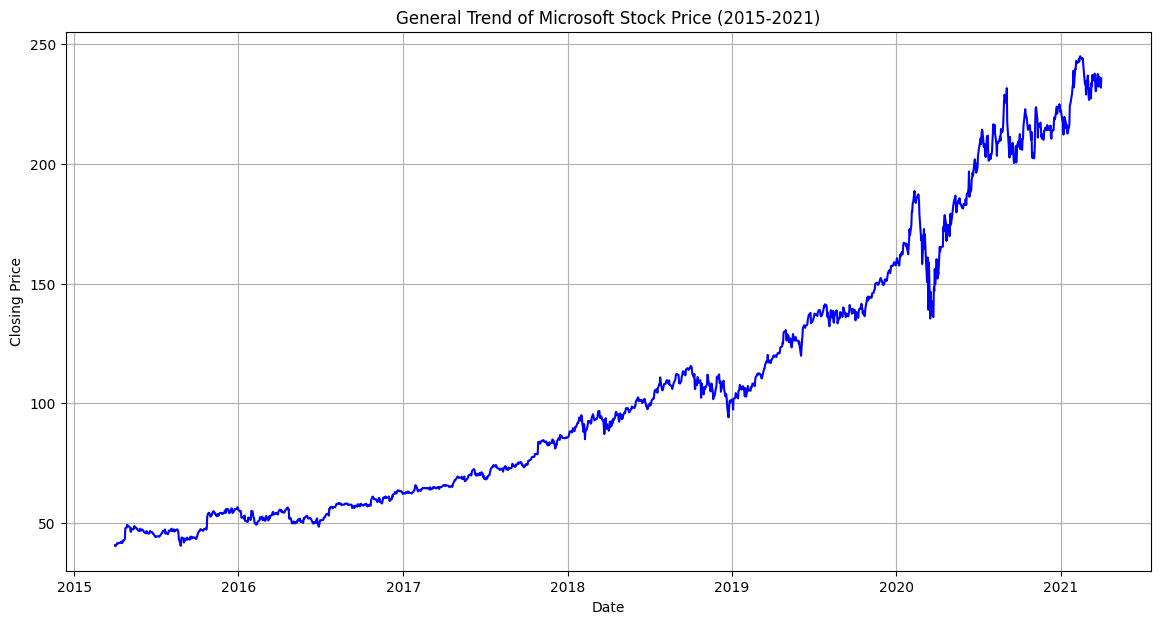

In [52]:
plt.figure(figsize=(14,7))
plt.plot(df['Date'], df['Close'], label='Closing Price', color='blue')
plt.title("General Trend of Microsoft Stock Price (2015-2021)")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)
plt.show()

In [53]:
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year
monthly_performance = df.groupby('Month')['Close'].mean().reset_index()
print("Average Monthly Performance: ")
print(monthly_performance)

Average Monthly Performance: 
    Month       Close
0       1  115.697851
1       2  121.646348
2       3  119.433258
3       4   91.864758
4       5   95.253543
5       6   98.247442
6       7  104.859449
7       8  104.957669
8       9  105.610984
9      10  108.346391
10     11  110.505285
11     12  113.881520


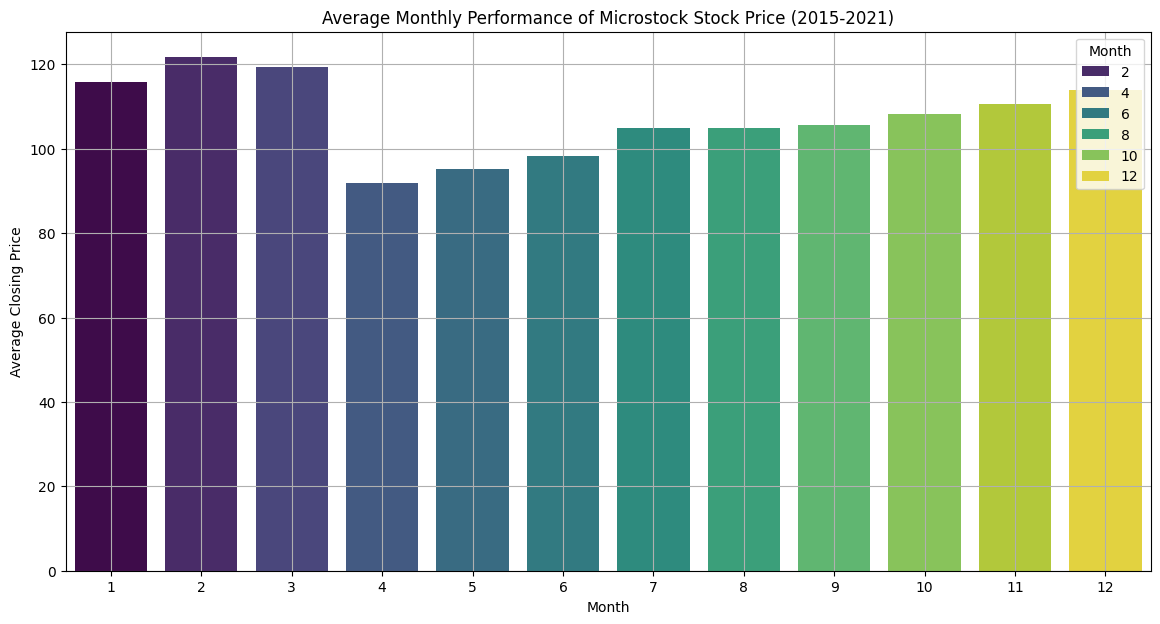

In [54]:
plt.figure(figsize=(14,7))
sns.barplot(data=monthly_performance, x='Month', y='Close', palette="viridis", hue='Month')
plt.title("Average Monthly Performance of Microstock Stock Price (2015-2021)")
plt.xlabel("Month")
plt.ylabel("Average Closing Price")
plt.grid(True)
plt.show()

# My Own Dataset, using XRP stock data


In [55]:
#My own stock/crypto

df_xrp = pd.read_csv("XRP_3Y.csv")
df_xrp.head()

,Date,Open,High,Low,Close
0,09/19/2025,3.1023,3.1023,2.9865,2.9880
1,09/18/2025,3.0166,3.1384,3.0078,3.1023
2,09/17/2025,3.0490,3.0689,2.9841,3.0175
3,09/16/2025,2.9985,3.0580,2.9662,3.0490
4,09/15/2025,3.0397,3.0670,2.9575,2.9982


In [56]:
df_xrp.isna().sum()

,0
Date,0
Open,0
High,0
Low,0
Close,0


In [57]:
df['Date'] = pd.to_datetime(df['Date'])
df_xrp = df.sort_values('Date')
df_xrp.head()

,Date,Open,High,Low,Close,Volume,Month,Year
0,2015-04-01 16:00:00,40.60,40.76,40.31,40.72,36865322,4,2015
1,2015-04-02 16:00:00,40.66,40.74,40.12,40.29,37487476,4,2015
2,2015-04-06 16:00:00,40.34,41.78,40.18,41.55,39223692,4,2015
3,2015-04-07 16:00:00,41.61,41.91,41.31,41.53,28809375,4,2015
4,2015-04-08 16:00:00,41.48,41.69,41.04,41.42,24753438,4,2015


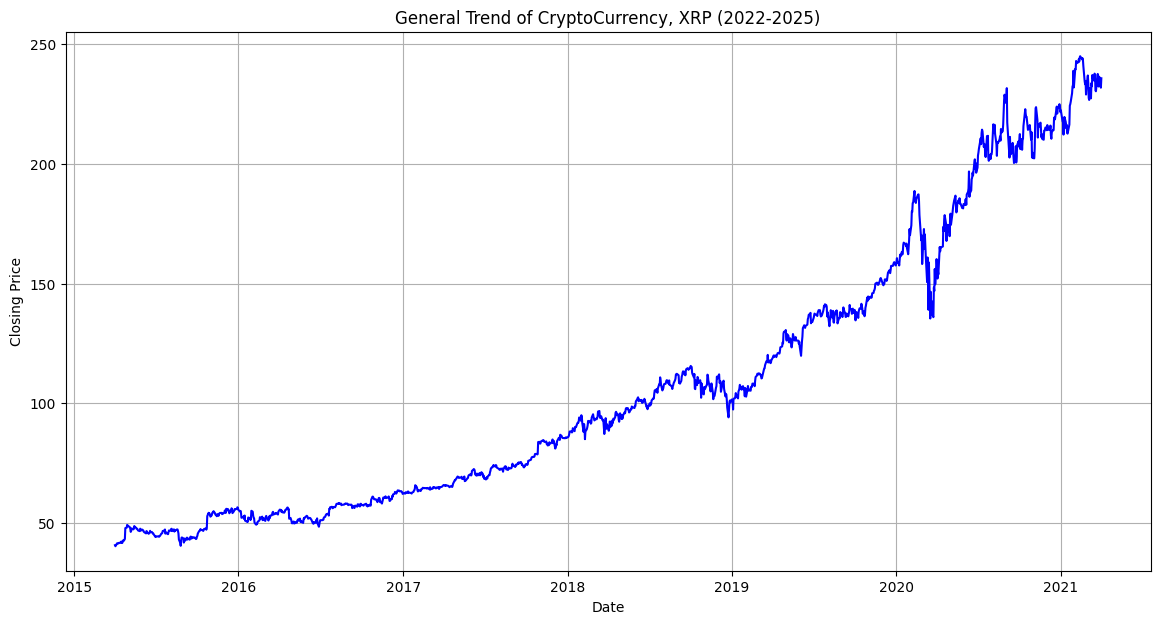

In [58]:
plt.figure(figsize=(14,7))
plt.plot(df_xrp['Date'], df_xrp['Close'], label='Closing Price', color='blue')
plt.title("General Trend of CryptoCurrency, XRP (2022-2025)")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)
plt.show()

In [16]:
# For data with null values, Fill with average or Grab, the next value or backward #
# df.fillna(method='ffill')
# df.fillna(method='bfill')

In [59]:
df_xrp["Month"] = df_xrp["Date"].dt.month
df_xrp["Year"] = df_xrp["Date"].dt.year
monthly_performance_xrp = df_xrp.groupby('Month')['Close'].mean().reset_index()
print("Average Monthly Performance: ")
print(monthly_performance_xrp)

Average Monthly Performance: 
    Month       Close
0       1  115.697851
1       2  121.646348
2       3  119.433258
3       4   91.864758
4       5   95.253543
5       6   98.247442
6       7  104.859449
7       8  104.957669
8       9  105.610984
9      10  108.346391
10     11  110.505285
11     12  113.881520


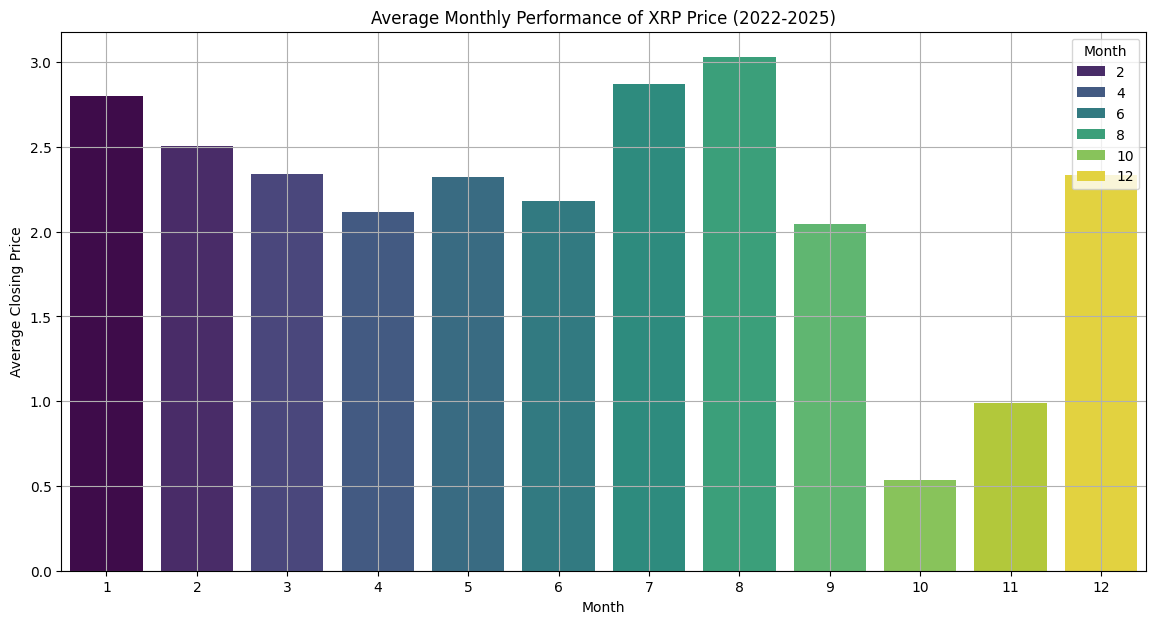

In [45]:
plt.figure(figsize=(14,7))
sns.barplot(data=monthly_performance_xrp, x='Month', y='Close', palette="viridis", hue='Month')
plt.title("Average Monthly Performance of XRP Price (2022-2025)")
plt.xlabel("Month")
plt.ylabel("Average Closing Price")
plt.grid(True)
plt.show()

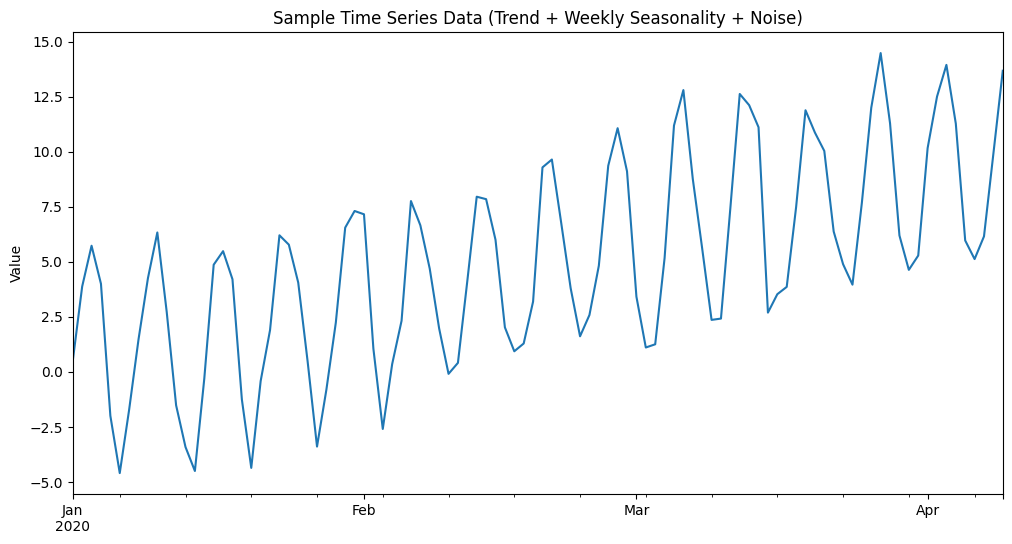

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
# Create a sample time series dataset: Trend + Seasonality + Noise
np.random.seed(42) # For reproducibility
date_range = pd.date_range(start='2020-01-01', periods=100, freq='D')
trend = np.linspace(0, 10, 100)
seasonality = 5 * np.sin(2 * np.pi * np.arange(100) / 7) # Weekly seasonality
noise = np.random.normal(0, 1, 100)
# Our synthetic data: sales over 100 days
data = trend + seasonality + noise
time_series = pd.Series(data, index=date_range)
# Plot it
plt.figure(figsize=(12, 6))
time_series.plot(title="Sample Time Series Data (Trend + Weekly Seasonality + Noise)")
plt.ylabel('Value')
plt.show()

In [62]:
model_ses = SimpleExpSmoothing(time_series)
fit_ses = model_ses.fit(smoothing_level=0.3, optimized=False) # Alpha = 0.3

# Make a forecasat for the next 5 periods
forecast_ses = fit_ses.forecast(5)
print(forecast_ses)

2020-04-10    9.872446
2020-04-11    9.872446
2020-04-12    9.872446
2020-04-13    9.872446
2020-04-14    9.872446
Freq: D, dtype: float64


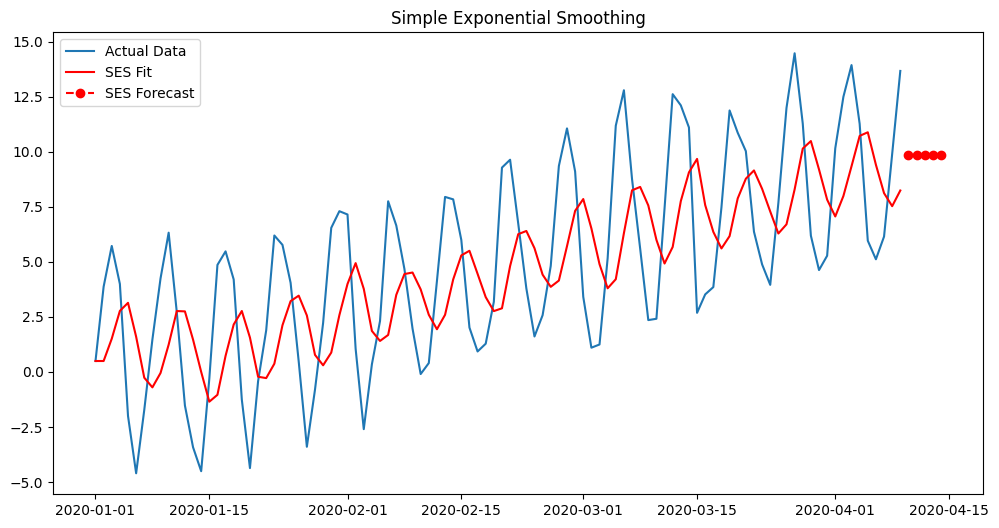

In [75]:
# Plot the results
plt.figure(figsize=(12,6))
plt.plot(time_series, label='Actual Data')
plt.plot(fit_ses.fittedvalues, label="SES Fit", color='red')
plt.plot(pd.date_range(time_series.index[-1] + pd.Timedelta(days=1), periods = 5, freq='D'),
          forecast_ses, label="SES Forecast", color='red', linestyle='--', marker="o")
plt.legend()
plt.title("Simple Exponential Smoothing")
plt.show()

2020-04-10    14.650414
2020-04-11    12.586340
2020-04-12     7.845971
2020-04-13     5.769792
2020-04-14     6.797191
Freq: D, dtype: float64


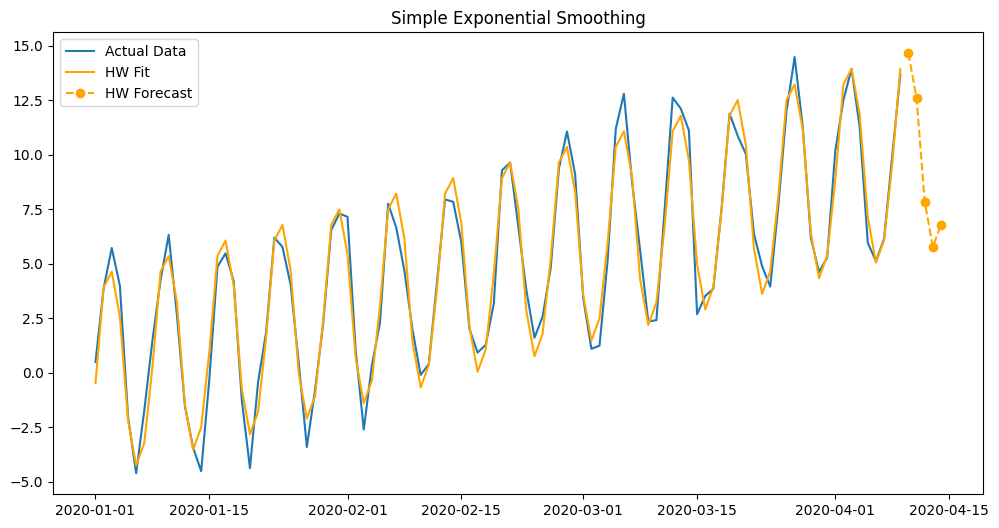

In [85]:
model_hw = ExponentialSmoothing(time_series,
                                 trend="add",
                                 seasonal="add",
                                 seasonal_periods=7
                                 )
fit_hw = model_hw.fit() # Alpha = 0.3

# Make a forecasat for the next 5 periods
forecast_hw = fit_hw.forecast(5)
print(forecast_hw)

# Plot the results
plt.figure(figsize=(12,6))
plt.plot(time_series, label='Actual Data')
plt.plot(fit_hw.fittedvalues, label="HW Fit", color='orange')
plt.plot(pd.date_range(time_series.index[-1] + pd.Timedelta(days=1), periods = 5, freq='D'),
          forecast_hw, label="HW Forecast", color='orange', linestyle='--', marker="o")
plt.legend()
plt.title("Simple Exponential Smoothing")
plt.show()